# 05 · PCA y mapas para visualizar
    **Objetivo.** Entender qué conservan PCA, t-SNE y (si está disponible) UMAP.
    Los colores vienen de k-means; no haremos clustering sobre el mapa ni
    tomaremos sus islas como prueba de objetos reales.

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Recuperamos la misma muestra
No volvemos a sortear puntos: cargamos los índices guardados en 01.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
sample_idx = np.load(OUT / 'sample_idx.npy')
assert len(np.unique(sample_idx)) == len(sample_idx)
xyz, rgb, normals = (cloud[key][sample_idx] for key in ('xyz', 'rgb', 'normals'))
print('Muestra común:', len(xyz), 'de', len(cloud['xyz']))

Muestra común: 93903 de 1647021


### PCA: las unidades cambian qué significa varianza
PCA encuentra direcciones de mayor varianza. Comparamos las features completas con y sin estandarizar. Los coeficientes (`components_.T`) muestran qué aporta cada variable a cada dirección; el signo de un eje se puede invertir sin cambiar la proyección.

In [4]:
FEATURES = {
    'xyz': {},
    'xyz+rgb': {'use_rgb': True},
    'xyz+normales': {'use_normals': True},
    'xyz+rgb+normales+height': {'use_rgb': True, 'use_normals': True, 'use_height': True},
}
def features(name, scaled=True):
    return build_features(xyz, rgb, normals, standardize=scaled, **FEATURES[name])
# Evaluación común: igual distancia y mismas filas para comparar métodos/features.
EVAL = features('xyz+rgb+normales+height')

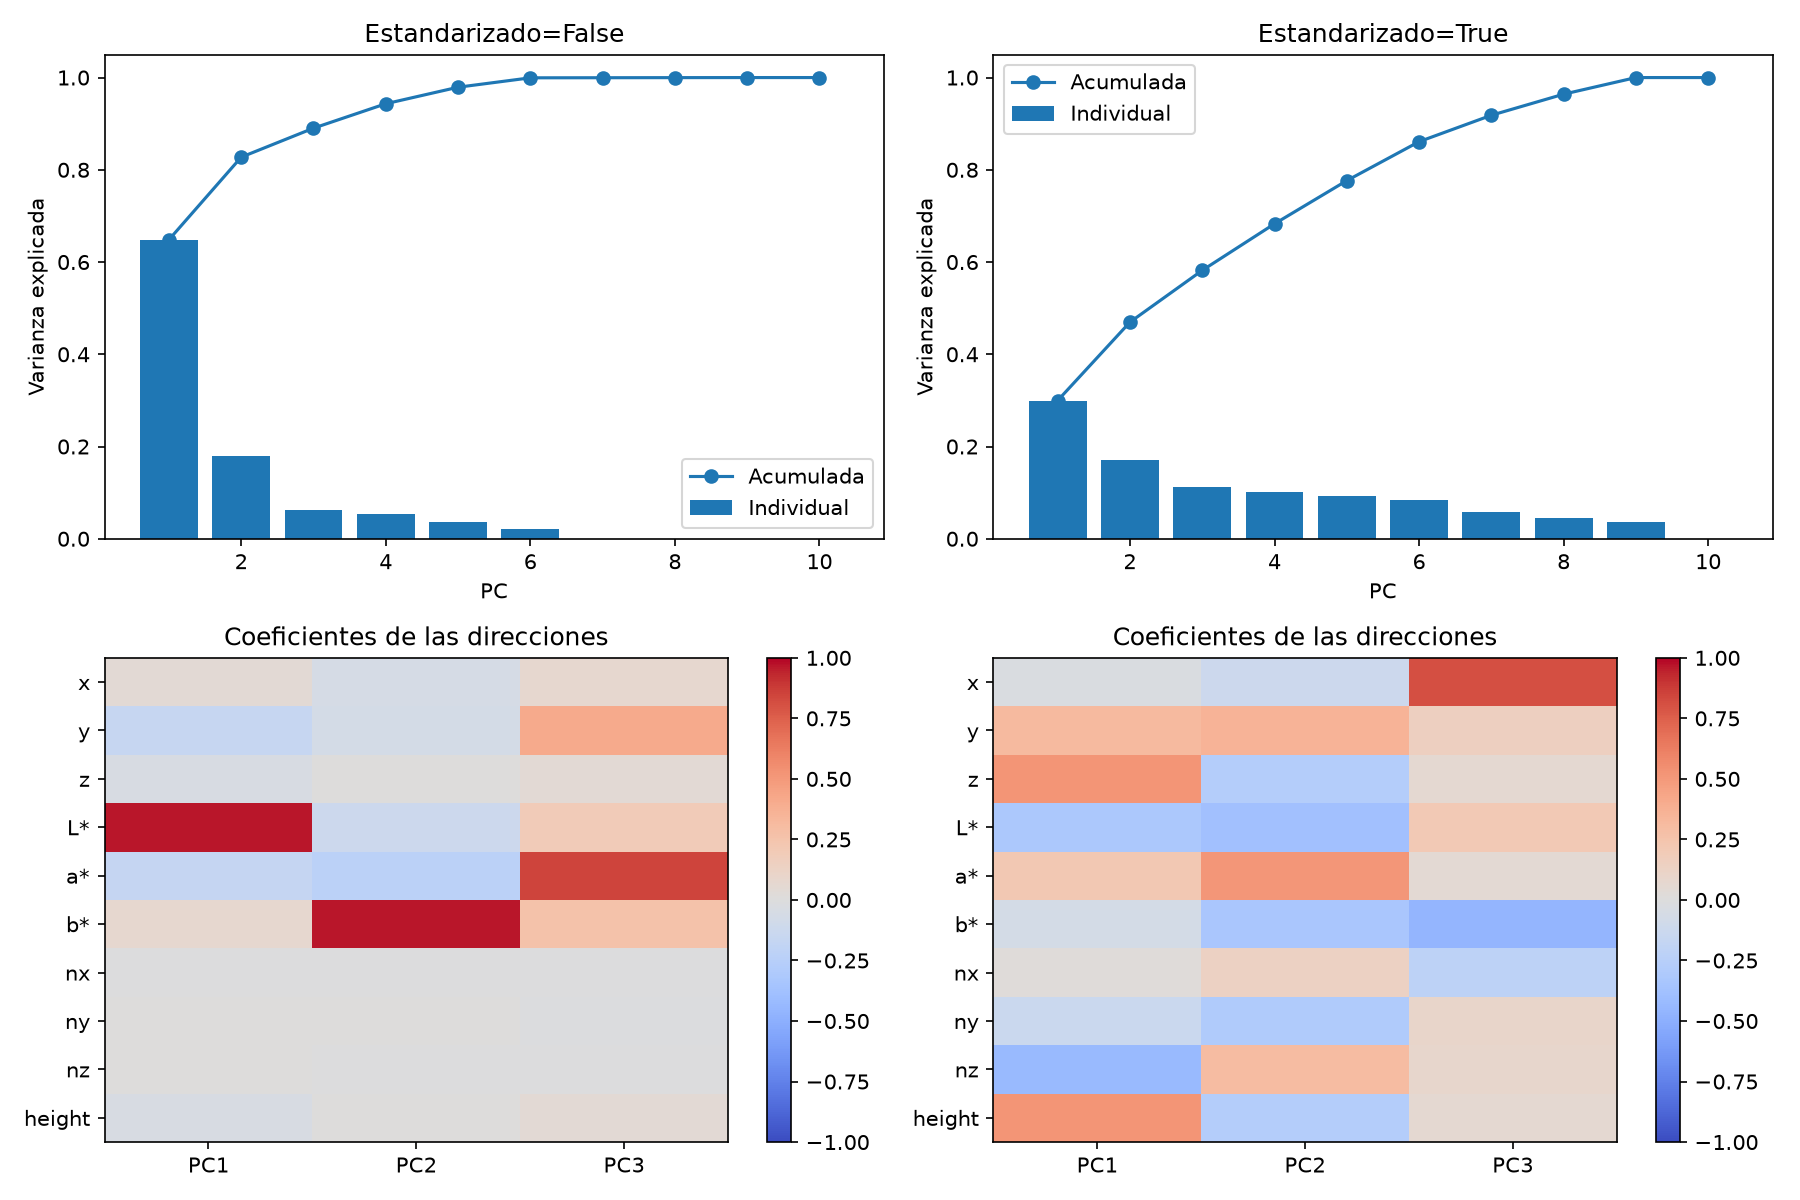

{'False': {'dos_pc': 0.8273697434151864, 'pc_90': 4, 'ratio': [0.6483497712782248, 0.17901997213696166, 0.06288307442453572, 0.052949380221106394, 0.035846492748275366, 0.020376422153587367, 0.00021274100427405197, 0.00020160819926843916, 0.00016053783376637992, 1.1735723873858891e-26]}, 'True': {'dos_pc': 0.4696440463413797, 'pc_90': 7, 'ratio': [0.29967292819429847, 0.16997111814708118, 0.11226338891070758, 0.10097640840614476, 0.09366703097802068, 0.08444362952887331, 0.05726546295223627, 0.04570741957072529, 0.03603261331191243, 1.78037578547346e-32]}}


In [5]:
from sklearn.decomposition import PCA
names = ['x','y','z','L*','a*','b*','nx','ny','nz','height']
pca_info = {}
fig, ax = plt.subplots(2,2,figsize=(12,8))
for j, scaled in enumerate((False,True)):
    X = features('xyz+rgb+normales+height',scaled)
    pca = PCA(svd_solver='full',random_state=0).fit(X)
    ratio = pca.explained_variance_ratio_
    pca_info[str(scaled)] = {'dos_pc':float(ratio[:2].sum()),
        'pc_90':int(np.searchsorted(np.cumsum(ratio),.90)+1), 'ratio':ratio.tolist()}
    ax[0,j].bar(range(1,len(ratio)+1),ratio,label='Individual')
    ax[0,j].plot(range(1,len(ratio)+1),np.cumsum(ratio),'o-',label='Acumulada')
    ax[0,j].set(xlabel='PC',ylabel='Varianza explicada',title=f'Estandarizado={scaled}'); ax[0,j].legend()
    im=ax[1,j].imshow(pca.components_[:3].T,aspect='auto',cmap='coolwarm',vmin=-1,vmax=1)
    ax[1,j].set(yticks=range(10),yticklabels=names,xticks=range(3),xticklabels=['PC1','PC2','PC3'],title='Coeficientes de las direcciones')
    fig.colorbar(im,ax=ax[1,j])
    pd.DataFrame(pca.components_.T,index=names).to_csv(CACHE/f'clase_pca_loadings_{scaled}.csv')
fig.tight_layout(); fig.savefig(FIG/'05_pca_varianza_loadings.png',dpi=150); display(Image(filename=str(FIG / '05_pca_varianza_loadings.png'))); plt.close(fig)
print(pca_info)

### Un mapa de 3000 puntos con colores fijos
Elegimos la corrida de k-means con mayor silhouette común, recuperamos sus etiquetas y dibujamos las mismas filas en todos los mapas. t-SNE preserva relaciones locales y puede deformar tamaños y distancias entre grupos. Probamos perplexity 15 y 40 para comprobar sensibilidad. Si no está umap-learn, lo omitimos sin instalar nada.

In [6]:
from sklearn.manifold import TSNE, trustworthiness
km = pd.read_csv(OUT/'metricas_02.csv').sort_values('silhouette_comun',ascending=False).iloc[0]
labels = np.load(LOGS/'clase_labels'/f'{km.id}.npy')
vis_idx = np.sort(np.random.default_rng(0).choice(len(xyz),min(3000,len(xyz)),replace=False))
np.save(CACHE/'clase_visualizacion_idx.npy',vis_idx)
Xvis = EVAL[vis_idx]
colors = segment_rgb(labels[vis_idx])/255
maps = {'PCA':PCA(n_components=2,svd_solver='full',random_state=0).fit_transform(Xvis)}
for perplexity in (15,40):
    maps[f't-SNE p={perplexity}'] = TSNE(n_components=2,perplexity=perplexity,
        init='pca',learning_rate='auto',max_iter=750,random_state=0).fit_transform(Xvis)
umap_available = importlib.util.find_spec('umap') is not None
if umap_available:
    from umap import UMAP
    maps['UMAP'] = UMAP(n_components=2,n_neighbors=15,min_dist=.1,random_state=0,n_jobs=1).fit_transform(Xvis)
else:
    print('umap-learn no está instalado: usamos solo t-SNE de sklearn; no se instala nada.')

umap-learn no está instalado: usamos solo t-SNE de sklearn; no se instala nada.


### ¿Cuánto se puede confiar en el vecindario dibujado?
Trustworthiness con 10 vecinos mide cuánto introduce el mapa vecinos que no eran cercanos en las features de origen. Es una medida del dibujo, no de calidad del clustering. PCA usa aquí las mismas 3000 filas para que la comparación sea directa.

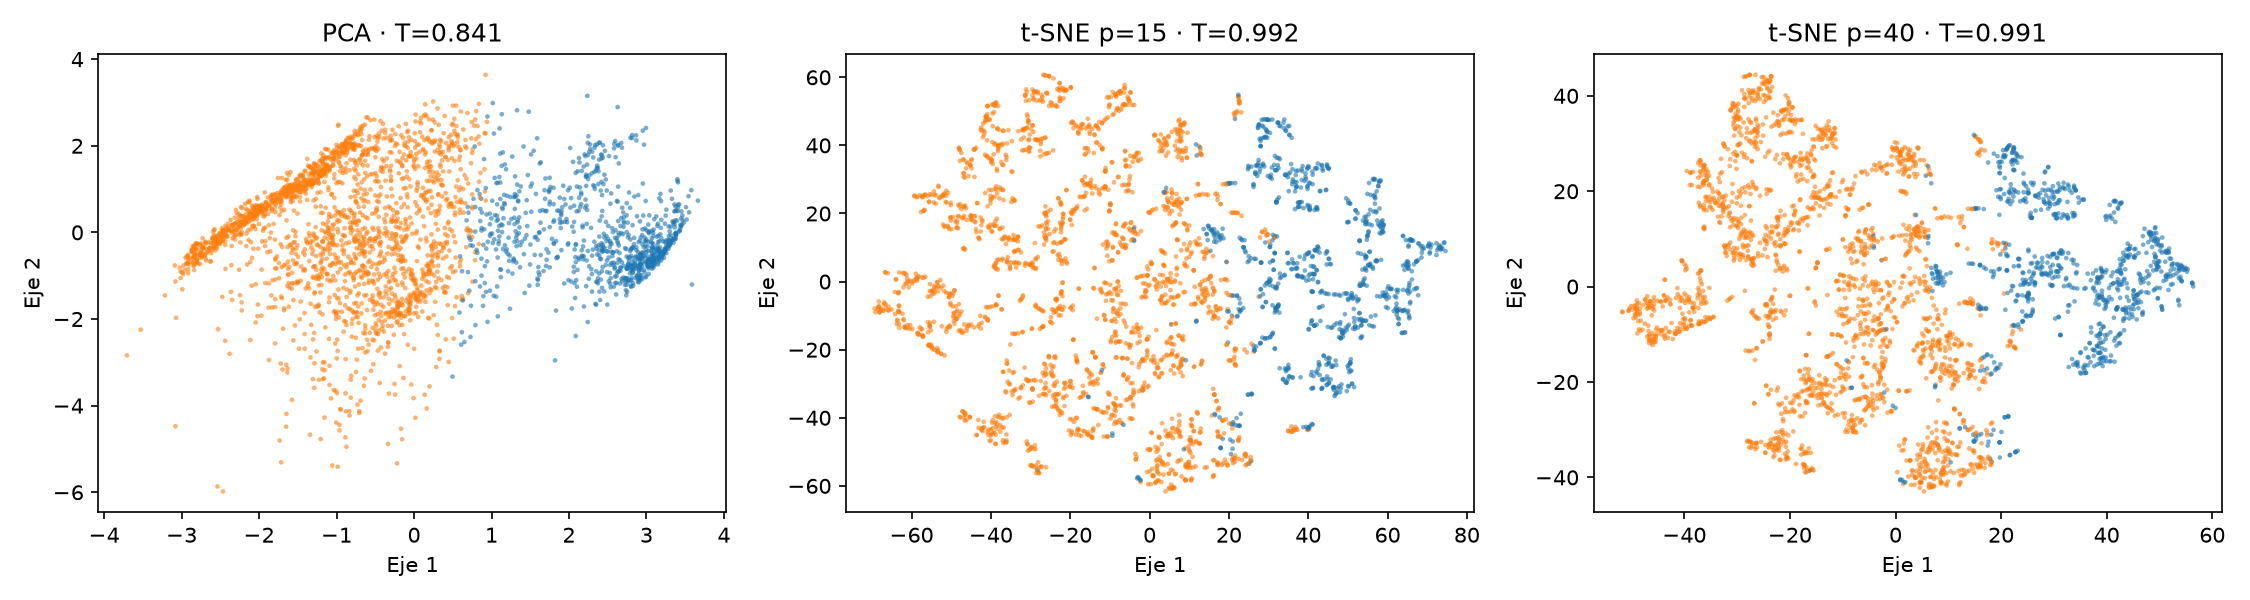

{'pca': {'False': {'dos_pc': 0.8273697434151864, 'pc_90': 4, 'ratio': [0.6483497712782248, 0.17901997213696166, 0.06288307442453572, 0.052949380221106394, 0.035846492748275366, 0.020376422153587367, 0.00021274100427405197, 0.00020160819926843916, 0.00016053783376637992, 1.1735723873858891e-26]}, 'True': {'dos_pc': 0.4696440463413797, 'pc_90': 7, 'ratio': [0.29967292819429847, 0.16997111814708118, 0.11226338891070758, 0.10097640840614476, 0.09366703097802068, 0.08444362952887331, 0.05726546295223627, 0.04570741957072529, 0.03603261331191243, 1.78037578547346e-32]}}, 'trustworthiness': {'PCA': 0.8405930083207684, 't-SNE p=15': 0.991871971854582, 't-SNE p=40': 0.9912712793879489}, 'umap': False, 'kmeans_id': '02_077', 'n_visualizacion': 3000, 'segundos_notebook': 10.414604603000043}


In [7]:
fig, axes = plt.subplots(1,len(maps),figsize=(5*len(maps),4))
scores = {}
for ax,(name,Z) in zip(np.atleast_1d(axes),maps.items()):
    scores[name] = float(trustworthiness(Xvis,Z,n_neighbors=10))
    ax.scatter(Z[:,0],Z[:,1],c=colors,s=5,alpha=.6,linewidths=0)
    ax.set(title=f'{name} · T={scores[name]:.3f}',xlabel='Eje 1',ylabel='Eje 2')
fig.tight_layout(); fig.savefig(FIG/'05_mapas.png',dpi=150); display(Image(filename=str(FIG / '05_mapas.png'))); plt.close(fig)
payload = dict(pca=pca_info, trustworthiness=scores, umap=umap_available,
               kmeans_id=km.id,n_visualizacion=len(vis_idx),segundos_notebook=time.perf_counter()-START)
(CACHE/'clase_resumen_05.json').write_text(json.dumps(payload,indent=2))
print(payload)

## Qué aprendimos / qué falló

Sin estandarizar, dos PC explicaron 82.7% de la varianza; estandarizando explicaron 47.0%. Para 90% se necesitaron 4 y 7 PC respectivamente. En 3000 puntos, trustworthiness fue PCA: 0.841, t-SNE p=15: 0.992, t-SNE p=40: 0.991. UMAP no estaba instalado y no instalamos paquetes. La última PC tiene varianza prácticamente cero, coherente con que height duplica z tras centrar. En los loadings sin escala, PC1 está dominada por L*; estandarizando, las normales también aportan. Los colores son etiquetas de k-means, no ground truth. Los mapas ayudan a explorar, pero no validan el número de grupos.